# Comprehension and Fixation Analysis

Exploratory plots, clustered models, and sensitivity diagnostics for the MECO-L2 participant-text data. The primary unit is one participant reading one text.

## Reproducibility

The notebook reads the count tables generated by `scripts/prepare_comprehension_fixations.py`. Run that preprocessing script first if the tables are absent. Generated figures and model tables are saved under `analysis/comprehension/output/notebook/`.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from analysis.comprehension.io import load_counts, sample_summary
from analysis.comprehension.models import fit_poisson_diagnostic, fit_primary, fit_reverse
from analysis.comprehension.plots import (
    plot_distributions, plot_jittered_association, plot_text_facets,
    plot_group_estimates, plot_language_text_heatmap, plot_participant_association,
    plot_model_diagnostics, plot_model_coefficients, plot_model_effects,
)

OUTPUT = ROOT / 'analysis' / 'comprehension' / 'output' / 'notebook'
PLOTS = OUTPUT / 'plots'
OUTPUT.mkdir(parents=True, exist_ok=True)
PLOTS.mkdir(parents=True, exist_ok=True)

In [2]:
data = load_counts('both')
print(f'Participant-text observations: {len(data):,}')
print(f'Participants: {data.participant_id.nunique():,}')
print(f'Texts: {data.text_id.nunique()}')
display(sample_summary(data))
data.to_csv(OUTPUT / 'analysis_dataset.csv', index=False)

Participant-text observations: 14,196
Participants: 1,200
Texts: 12


,wave,lang,participants,participant_text_rows,texts,mean_comprehension,mean_fixations_per_word
0,1,du,46,552,12,0.742754,1.202702
1,1,ee,58,696,12,0.781609,1.301527
2,1,en,45,540,12,0.737037,0.993022
3,1,fi,51,612,12,0.750817,1.216215
4,1,ge,45,540,12,0.730556,1.399680
5,1,gr,48,575,12,0.582609,1.332026
6,1,he,45,540,12,0.744444,1.678735
7,1,it,51,611,12,0.725859,1.530587
8,1,no,40,480,12,0.664583,1.298869
9,1,ru,47,564,12,0.746454,1.344046


## Data Quality and Coverage

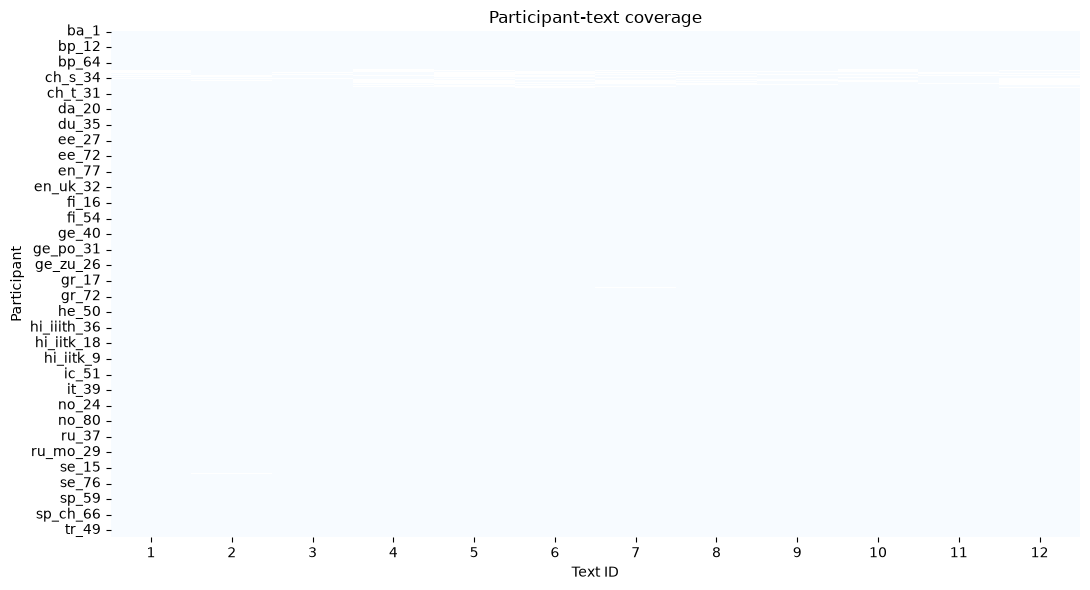

,wave,out_rows,ps_missing_rows,duration_extreme_rows
count,14196.000000,14196.000000,14196.000000,14196.00000
mean,1.542054,0.094463,5.097492,0.00958
std,0.498246,1.258947,33.918533,0.12067
min,1.000000,0.000000,0.000000,0.00000
25%,1.000000,0.000000,0.000000,0.00000
50%,2.000000,0.000000,0.000000,0.00000
75%,2.000000,0.000000,0.000000,0.00000
max,2.000000,100.000000,499.000000,4.00000


In [3]:
coverage = data.pivot_table(index='participant_id', columns='text_id', values='comprehension_score', aggfunc='size')
fig, ax = plt.subplots(figsize=(11, 6))
import seaborn as sns
sns.heatmap(coverage, cmap='Blues', cbar=False, ax=ax)
ax.set(title='Participant-text coverage', xlabel='Text ID', ylabel='Participant')
fig.tight_layout()
fig.savefig(PLOTS / 'participant_text_coverage.png', dpi=160)
display(fig)
plt.close(fig)
display(data[['wave', 'out_rows', 'ps_missing_rows', 'duration_extreme_rows']].describe())

## Distributions

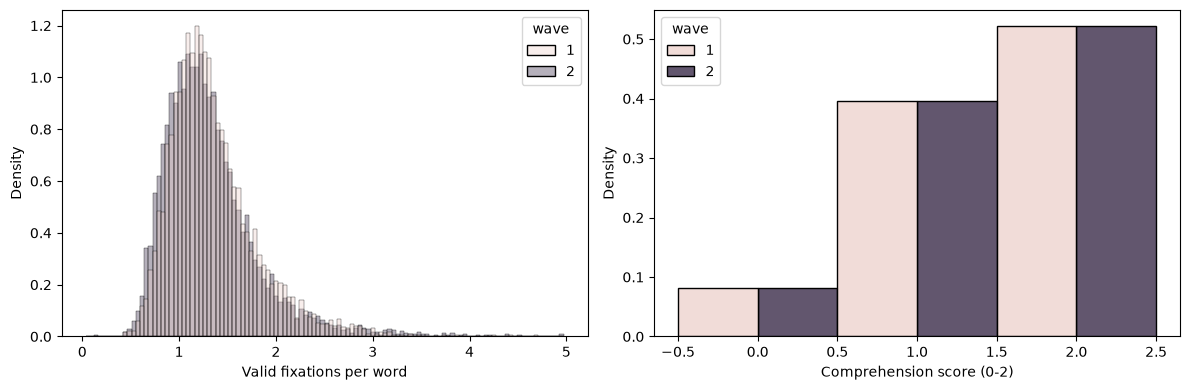

In [4]:
fig = plot_distributions(data, PLOTS)
display(fig)
plt.close(fig)

## Main Associations

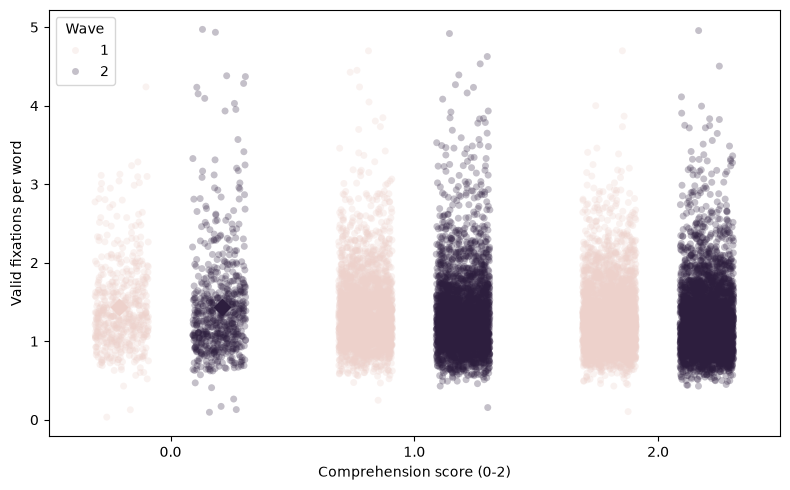

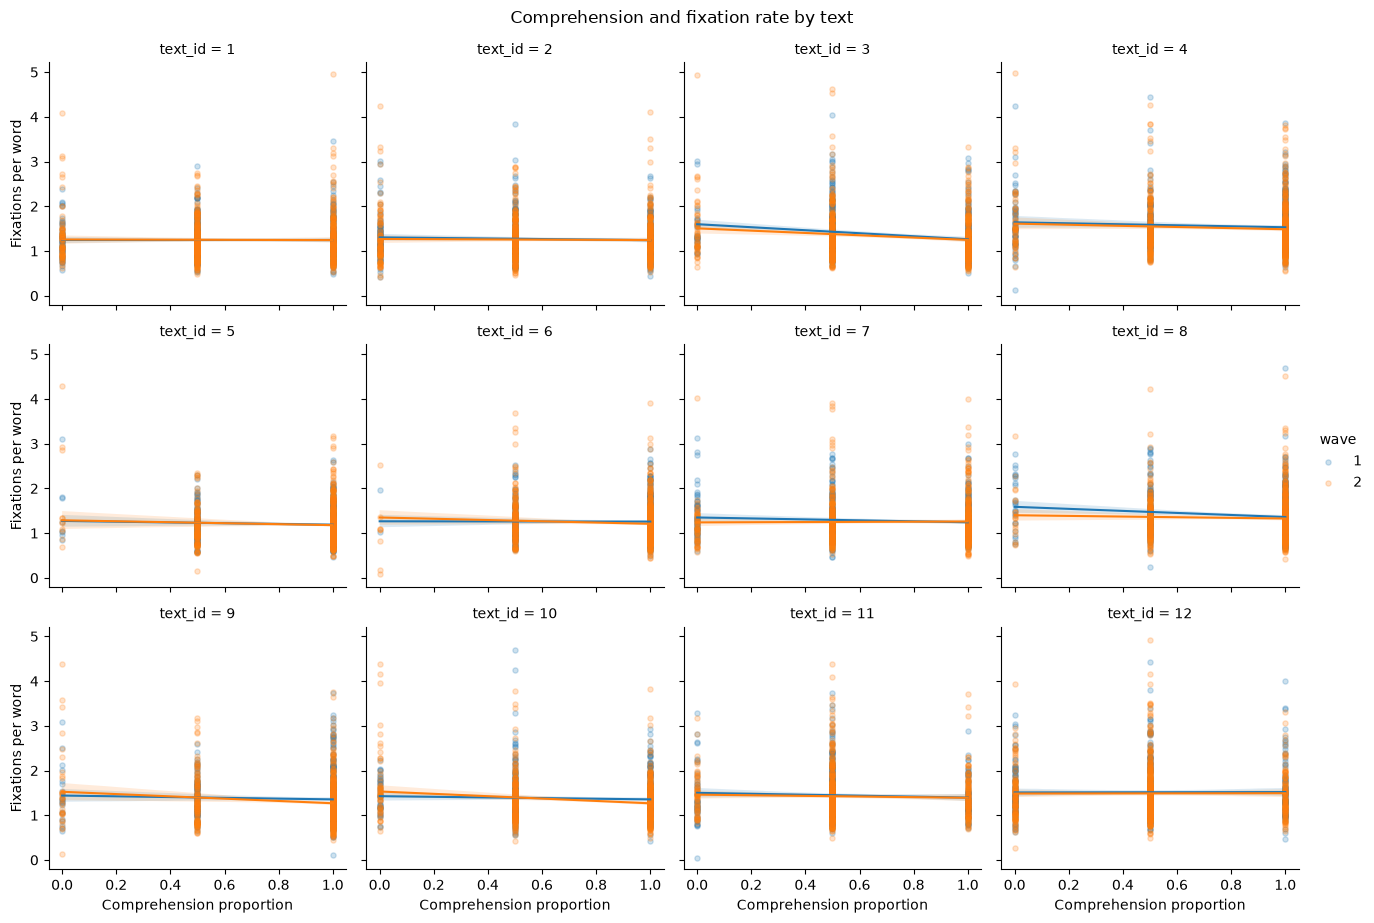

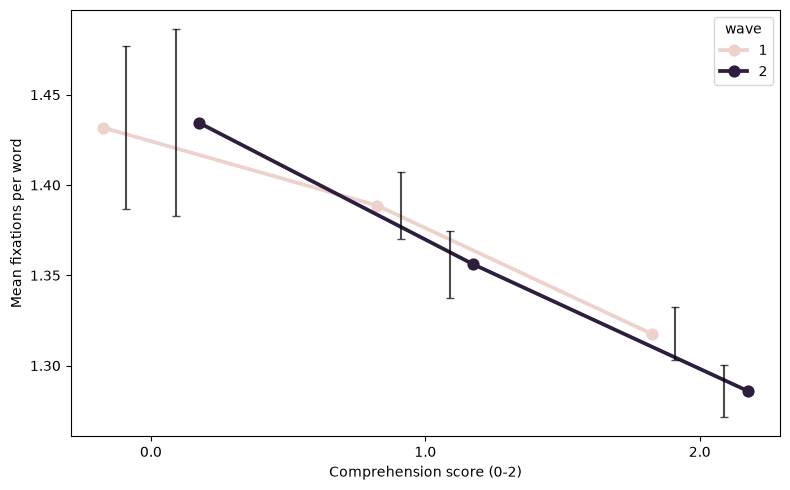

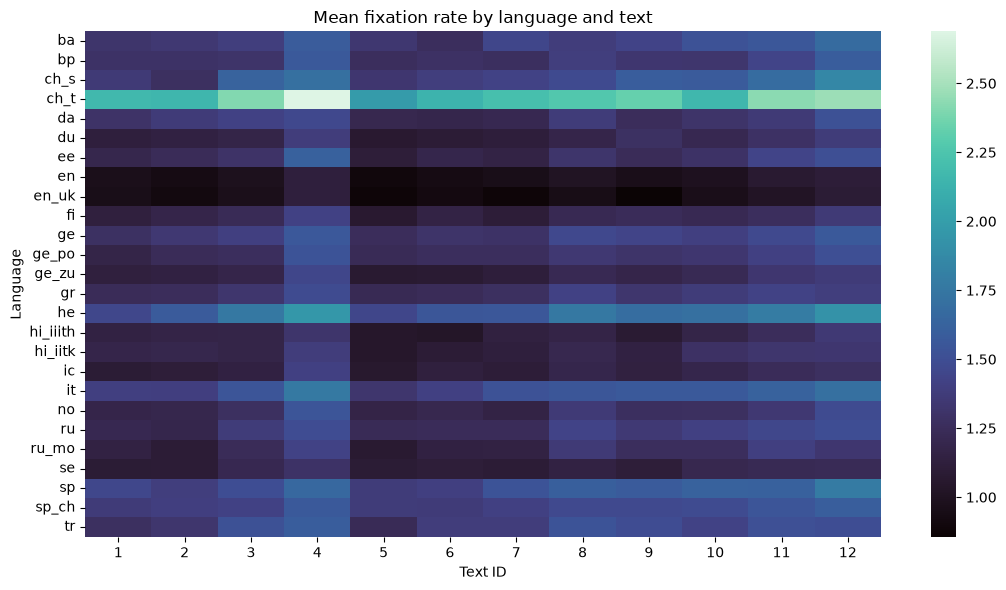

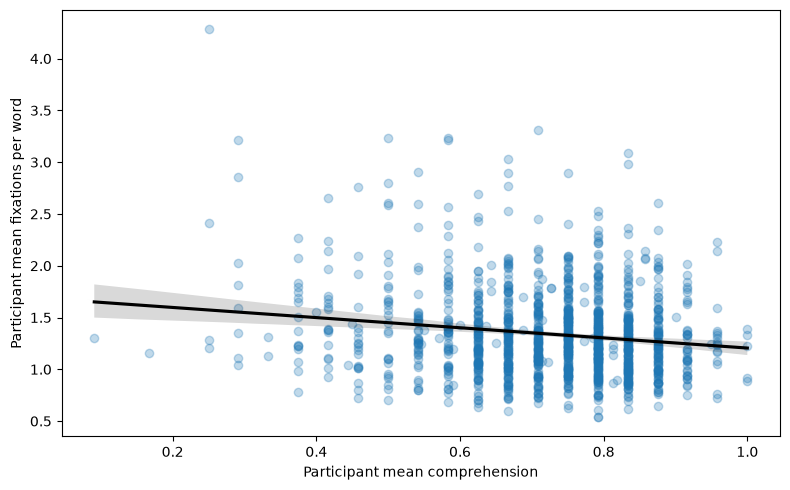

In [5]:
for plotter in (plot_jittered_association, plot_text_facets, plot_group_estimates, plot_language_text_heatmap, plot_participant_association):
    fig = plotter(data, PLOTS)
    display(fig)
    plt.close(fig)

## Clustered Models

The primary model is a negative-binomial GEE with participant clusters, text length as an offset, and language, wave, and text controls. The reverse model expands each 0-2 score into two Bernoulli question outcomes.

In [6]:
poisson = fit_poisson_diagnostic(data)
primary = fit_primary(data)
reverse = fit_reverse(data)
print('Poisson Pearson dispersion:', (poisson.resid_pearson ** 2).sum() / poisson.df_resid)
display(pd.DataFrame({'term': primary.params.index, 'estimate': primary.params.values, 'p_value': primary.pvalues.values, 'rate_ratio': __import__('numpy').exp(primary.params.values)}))
display(pd.DataFrame({'term': reverse.params.index, 'estimate': reverse.params.values, 'p_value': reverse.pvalues.values, 'odds_ratio': __import__('numpy').exp(reverse.params.values)}))

Poisson Pearson dispersion: 16.227014395574386


,term,estimate,p_value,rate_ratio
0,Intercept,0.383570,2.150810e-08,1.467514
1,C(wave)[T.2],-0.087814,1.129866e-01,0.915931
2,C(lang)[T.bp],-0.052210,3.090306e-01,0.949129
3,C(lang)[T.ch_s],0.067266,2.083326e-01,1.069580
4,C(lang)[T.ch_t],0.461575,2.975272e-14,1.586570
5,C(lang)[T.da],-0.077362,2.075418e-01,0.925555
6,C(lang)[T.du],-0.267770,5.525343e-04,0.765083
7,C(lang)[T.ee],-0.190646,1.186002e-02,0.826425
8,C(lang)[T.en],-0.458206,1.117289e-09,0.632417
9,C(lang)[T.en_uk],-0.407941,9.144773e-15,0.665018


,term,estimate,p_value,odds_ratio
0,Intercept,0.609925,4.286988e-04,1.840293
1,C(wave)[T.2],0.270030,3.118235e-02,1.310004
2,C(lang)[T.bp],0.113618,3.805406e-01,1.120324
3,C(lang)[T.ch_s],-0.170339,2.387474e-01,0.843379
4,C(lang)[T.ch_t],-0.308835,4.745108e-02,0.734302
5,C(lang)[T.da],-0.067359,6.315063e-01,0.934860
6,C(lang)[T.du],0.229648,1.899526e-01,1.258157
7,C(lang)[T.ee],0.493259,5.361263e-03,1.637645
8,C(lang)[T.en],0.183370,3.299633e-01,1.201258
9,C(lang)[T.en_uk],-0.111906,3.646594e-01,0.894128


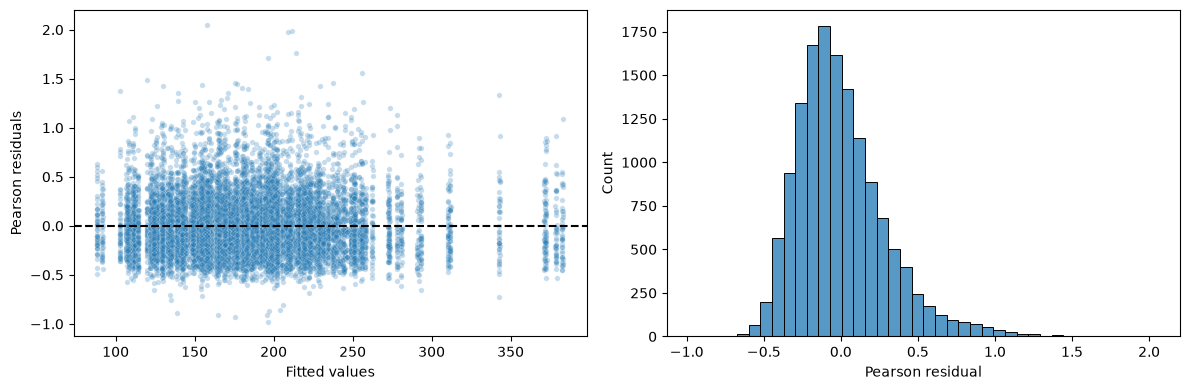

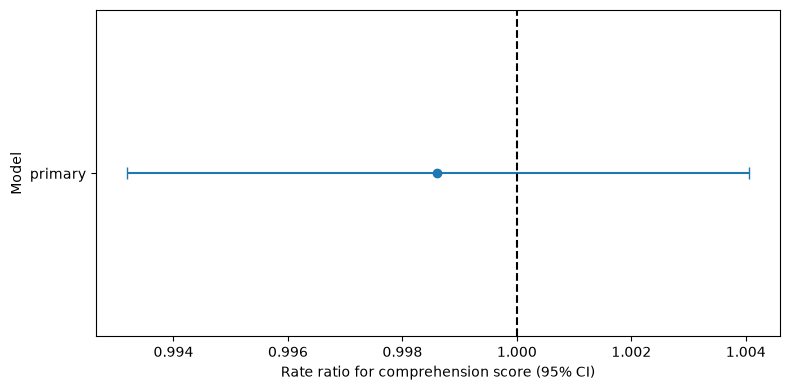

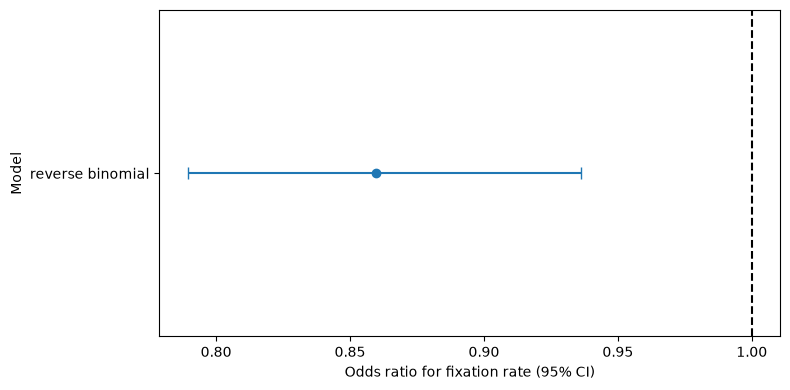

In [7]:
fig = plot_model_diagnostics(primary, PLOTS)
display(fig)
plt.close(fig)
fig = plot_model_coefficients({'primary': primary}, PLOTS)
display(fig)
plt.close(fig)
fig = plot_model_effects({'reverse binomial': reverse}, 'fixations_per_word', PLOTS, filename='reverse_model_odds_ratio.png', xlabel='Odds ratio for fixation rate (95% CI)')
display(fig)
plt.close(fig)

## Sensitivity Analysis

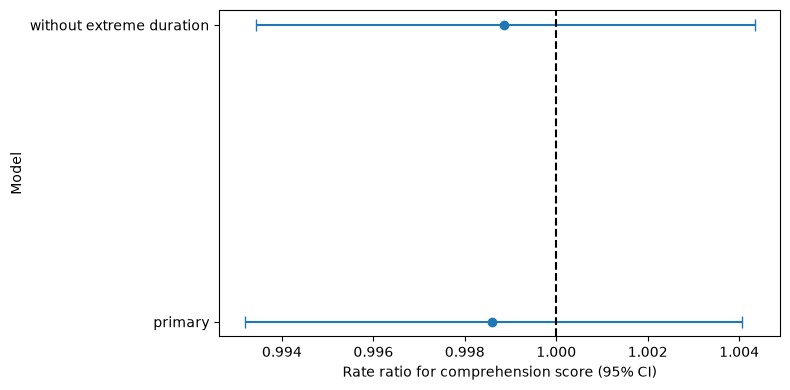

,model,estimate,rate_ratio,p_value
0,primary,-0.001397,0.998604,0.614878
1,without extreme duration,-0.001135,0.998866,0.683740


In [8]:
sensitivity_data = data[data['duration_extreme_rows'] == 0].copy()
sensitivity = fit_primary(sensitivity_data)
fig = plot_model_coefficients({'primary': primary, 'without extreme duration': sensitivity}, PLOTS)
display(fig)
plt.close(fig)
display(pd.DataFrame({
    'model': ['primary', 'without extreme duration'],
    'estimate': [primary.params['comprehension_score'], sensitivity.params['comprehension_score']],
    'rate_ratio': [__import__('numpy').exp(primary.params['comprehension_score']), __import__('numpy').exp(sensitivity.params['comprehension_score'])],
    'p_value': [primary.pvalues['comprehension_score'], sensitivity.pvalues['comprehension_score']],
}))

## Interpretation

Interpret the comprehension coefficient as an association in fixation rate, not a causal effect. Check whether its direction and confidence interval remain stable across waves, texts, languages, and quality sensitivity analyses before drawing conclusions.